# SaúdeScope
## Notebook 03 — Análise Exploratória de Dados (EDA)

**Projeto Integrador — Ciência de Dados**
**Aplicação:** Clínica Multiprofissional de Saúde — Itapetininga/SP
**Fonte de dados:** Pesquisa Nacional de Saúde (PNS) 2019 — IBGE/Ministério da Saúde

---


## 1. Objetivo deste notebook

Os notebooks anteriores entregaram uma base tratada e prevalências ponderadas corretas
(`02_limpeza_e_tratamento.ipynb`). Este notebook aprofunda a análise exploratória em três
frentes, com um objetivo concreto ao final: **preparar as variáveis que alimentarão o modelo
de Machine Learning do notebook 04**.

1. **Perfil sociodemográfico** — como as condições de saúde se distribuem por sexo, raça/cor
   e escolaridade, para além da distribuição por faixa etária já vista no notebook 02;
2. **Multimorbidade** — quantas pessoas acumulam duas ou mais doenças crônicas simultaneamente,
   e como isso se relaciona ao estado nutricional;
3. **Correlação entre variáveis** — quais condições tendem a co-ocorrer, e quais variáveis
   sociodemográficas mais se relacionam com os desfechos de saúde, informando a escolha de
   features para o modelo preditivo.

Ao final, exportamos uma base "pronta para modelagem", com variáveis categóricas codificadas
numericamente e um relatório claro de quais variáveis serão usadas como *features* e qual será
o *alvo* (variável-resposta) do modelo do próximo notebook.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

PROCESSED_DIR = Path("data/processed")
np.random.seed(42)

df = pd.read_parquet(PROCESSED_DIR / "pns_2019_sp_tratado.parquet")
print("Base carregada:", df.shape)
df.head()


Base carregada: (17522, 33)


,V0001,V0024,UPA_PNS,V0006_PNS,V0015,C00301,C006,C008,C009,P00403,P00404,Q00201,Q03001,Q068,Q092,Q11006,Q124,W00103,W00203,V00281,VDD004A,hipertensao,diabetes,avc,depressao,outra_doenca_mental,insuficiencia_renal,sexo,cor_raca,instrucao,faixa_etaria,imc,imc_classificacao
0,35,3510111,350000261,0001,01,01,2,33,1,170,170,2,2,2,2,1,2,NaN,NaN,4892.428417,7,Não,Não,Não,Não,Sim,Não,Mulher,Branca,Superior completo,Adulto (18-59),<NA>,NaN
1,35,3510111,350000261,0002,01,01,2,44,1,163,163,2,2,2,1,1,2,NaN,NaN,4892.428417,7,Não,Não,Não,Sim,Sim,Não,Mulher,Branca,Superior completo,Adulto (18-59),<NA>,NaN
2,35,3510111,350000261,0002,01,02,1,41,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,7,NaN,NaN,NaN,NaN,NaN,NaN,Homem,Branca,Superior completo,Adulto (18-59),<NA>,NaN
3,35,3510111,350000261,0002,01,03,2,5,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,1,NaN,NaN,NaN,NaN,NaN,NaN,Mulher,Branca,Sem instrução,Criança (0-11),<NA>,NaN
4,35,3510111,350000261,0006,01,01,1,64,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,7,NaN,NaN,NaN,NaN,NaN,NaN,Homem,Branca,Superior completo,Idoso (60+),<NA>,NaN


## 2. Perfil sociodemográfico da amostra

Antes de cruzar variáveis, vale entender a composição da amostra de São Paulo em termos de
sexo, raça/cor e escolaridade — o "quem" por trás dos números de prevalência.


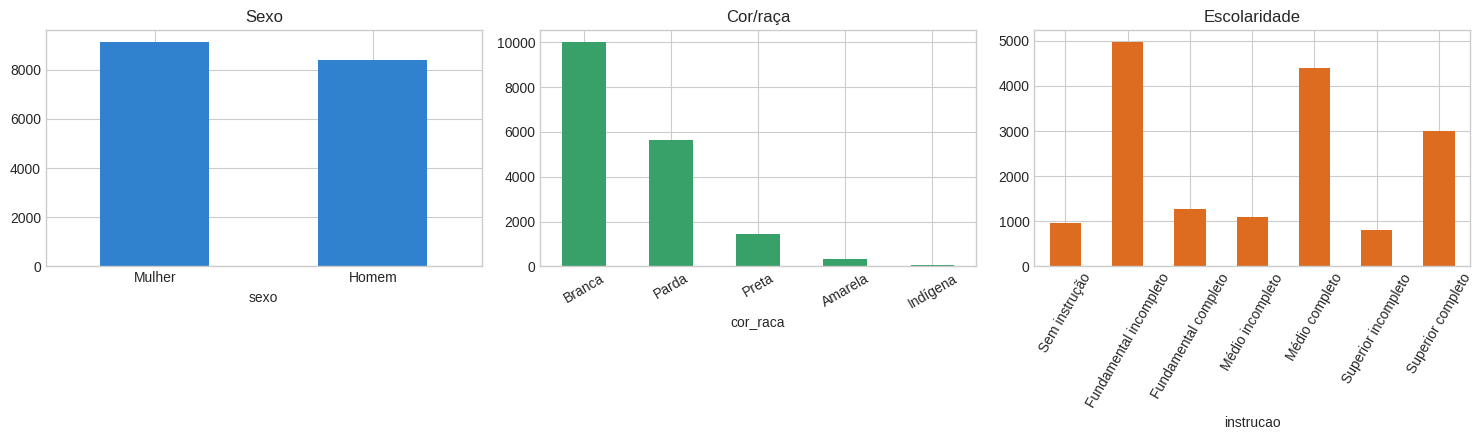

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

df["sexo"].value_counts().plot(kind="bar", ax=axes[0], color="#3182ce")
axes[0].set_title("Sexo")
axes[0].tick_params(axis="x", rotation=0)

df["cor_raca"].value_counts().plot(kind="bar", ax=axes[1], color="#38a169")
axes[1].set_title("Cor/raça")
axes[1].tick_params(axis="x", rotation=30)

ordem_instrucao = ["Sem instrução", "Fundamental incompleto", "Fundamental completo",
                    "Médio incompleto", "Médio completo", "Superior incompleto", "Superior completo"]
df["instrucao"].value_counts().reindex(ordem_instrucao).plot(kind="bar", ax=axes[2], color="#dd6b20")
axes[2].set_title("Escolaridade")
axes[2].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_perfil_sociodemografico.png", dpi=150)
plt.show()


## 3. Prevalência ponderada por sexo, raça/cor e escolaridade

Reaproveitamos a função de prevalência ponderada já validada no notebook 02, agora aplicada a
três recortes sociodemográficos adicionais à faixa etária.


In [3]:
def prevalencia_ponderada(coluna_sim_nao: pd.Series, peso: pd.Series) -> float:
    """Prevalência ponderada (%) entre respondentes válidos; NaN se não houver nenhum."""
    valido = coluna_sim_nao.notna()
    if valido.sum() == 0:
        return np.nan
    positivos = (coluna_sim_nao == "Sim").astype(int)
    return np.average(positivos[valido], weights=peso[valido]) * 100


condicoes = {
    "hipertensao": "Hipertensão", "diabetes": "Diabetes", "depressao": "Depressão",
    "outra_doenca_mental": "Outra doença mental", "avc": "AVC/derrame",
    "insuficiencia_renal": "Insuficiência renal",
}

def tabela_por_grupo(coluna_grupo, categorias=None):
    grupos = categorias if categorias else df[coluna_grupo].dropna().unique()
    linhas = {}
    for nome_var, rotulo in condicoes.items():
        linhas[rotulo] = [
            prevalencia_ponderada(df.loc[df[coluna_grupo] == g, nome_var], df.loc[df[coluna_grupo] == g, "V00281"])
            for g in grupos
        ]
    return pd.DataFrame(linhas, index=grupos).round(1)


tabela_sexo = tabela_por_grupo("sexo", ["Homem", "Mulher"])
print("=== Prevalência ponderada por sexo (%) ===")
tabela_sexo


=== Prevalência ponderada por sexo (%) ===


,Hipertensão,Diabetes,Depressão,Outra doença mental,AVC/derrame,Insuficiência renal
Homem,24.3,9.9,6.1,4.7,2.5,1.3
Mulher,31.3,10.6,17.6,10.1,1.8,1.6


In [4]:
tabela_raca = tabela_por_grupo("cor_raca", ["Branca", "Preta", "Parda"])
print("=== Prevalência ponderada por raça/cor (%) — categorias com n amostral suficiente ===")
tabela_raca


=== Prevalência ponderada por raça/cor (%) — categorias com n amostral suficiente ===


,Hipertensão,Diabetes,Depressão,Outra doença mental,AVC/derrame,Insuficiência renal
Branca,27.6,10.6,14.1,8.7,1.8,1.5
Preta,34.3,9.5,9.1,6.4,3.0,1.6
Parda,27.2,9.8,10.7,6.4,2.2,1.4


In [5]:
df["escolaridade_grp"] = df["instrucao"].map({
    "Sem instrução": "Fund. incompleto ou menos",
    "Fundamental incompleto": "Fund. incompleto ou menos",
    "Fundamental completo": "Fund. completo/Médio incompleto",
    "Médio incompleto": "Fund. completo/Médio incompleto",
    "Médio completo": "Médio completo/Superior incompleto",
    "Superior incompleto": "Médio completo/Superior incompleto",
    "Superior completo": "Superior completo",
})
ordem_esc = ["Fund. incompleto ou menos", "Fund. completo/Médio incompleto",
             "Médio completo/Superior incompleto", "Superior completo"]

tabela_escolaridade = tabela_por_grupo("escolaridade_grp", ordem_esc)
print("=== Prevalência ponderada por escolaridade agrupada (%) ===")
tabela_escolaridade


=== Prevalência ponderada por escolaridade agrupada (%) ===


,Hipertensão,Diabetes,Depressão,Outra doença mental,AVC/derrame,Insuficiência renal
Fund. incompleto ou menos,44.2,18.4,12.7,5.7,4.7,2.0
Fund. completo/Médio incompleto,28.4,8.9,12.4,7.0,1.6,2.2
Médio completo/Superior incompleto,20.9,7.3,10.7,8.1,0.9,0.9
Superior completo,19.3,6.0,15.0,10.0,0.9,1.0


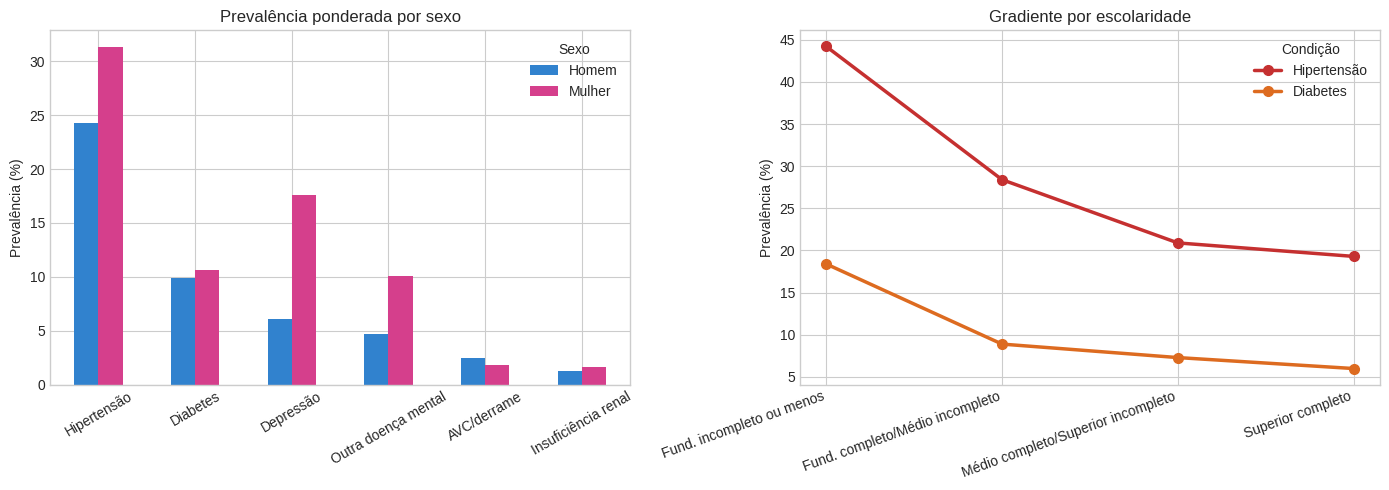

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabela_sexo.T.plot(kind="bar", ax=axes[0], color=["#3182ce", "#d53f8c"])
axes[0].set_title("Prevalência ponderada por sexo")
axes[0].set_ylabel("Prevalência (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Sexo")

tabela_escolaridade[["Hipertensão", "Diabetes"]].plot(kind="line", marker="o", ax=axes[1],
                                                        linewidth=2.5, markersize=7, color=["#c53030", "#dd6b20"])
axes[1].set_title("Gradiente por escolaridade")
axes[1].set_ylabel("Prevalência (%)")
axes[1].set_xticks(range(len(ordem_esc)))
axes[1].set_xticklabels(ordem_esc, rotation=20, ha="right")
axes[1].legend(title="Condição")

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_eda_sexo_escolaridade.png", dpi=150)
plt.show()


> **Leitura:** a disparidade de sexo é muito mais marcante em saúde mental (depressão quase
> 3 vezes mais prevalente em mulheres) do que em hipertensão/diabetes. Já a escolaridade mostra
> um gradiente forte e consistente para as DCNT — quanto menor a escolaridade, maior a
> prevalência —, um padrão que a literatura atribui em parte ao envelhecimento médio mais
> avançado nos estratos de menor escolaridade no Brasil, e não apenas a um efeito direto da
> educação em si.


## 4. Multimorbidade: coexistência de doenças crônicas

Uma pessoa pode ter mais de uma DCNT ao mesmo tempo. Construímos um índice simples somando o
número de diagnósticos entre as quatro DCNT mapeadas (hipertensão, diabetes, AVC e insuficiência
renal), restrito à população adulta e idosa — público onde essas perguntas são de fato
aplicáveis.


In [7]:
pop_adulta = df[df["faixa_etaria"].isin(["Adulto (18-59)", "Idoso (60+)"])].copy()

dcnt_cols = ["hipertensao", "diabetes", "avc", "insuficiencia_renal"]

def conta_condicoes(row):
    valores = [row[c] for c in dcnt_cols]
    if all(pd.isna(v) for v in valores):
        return np.nan
    return sum(1 for v in valores if v == "Sim")

pop_adulta["n_dcnt"] = pop_adulta.apply(conta_condicoes, axis=1)

valido = pop_adulta["n_dcnt"].notna()
peso = pop_adulta.loc[valido, "V00281"]
n_dcnt = pop_adulta.loc[valido, "n_dcnt"].clip(upper=3)

distribuicao_multimorbidade = pd.Series({
    k: np.average((n_dcnt == k).astype(int), weights=peso) * 100 for k in [0, 1, 2, 3]
})
distribuicao_multimorbidade.index = ["Nenhuma", "1 condição", "2 condições", "3 ou mais"]

print("Distribuição ponderada do número de DCNT (adultos e idosos):")
print(distribuicao_multimorbidade.round(1))

multimorbidade_pct = np.average((n_dcnt >= 2).astype(int), weights=peso) * 100
print(f"\nPrevalência de multimorbidade (2+ DCNT): {multimorbidade_pct:.1f}%")


Distribuição ponderada do número de DCNT (adultos e idosos):
Nenhuma        66.7
1 condição     25.1
2 condições     7.6
3 ou mais       0.6
dtype: float64

Prevalência de multimorbidade (2+ DCNT): 8.2%


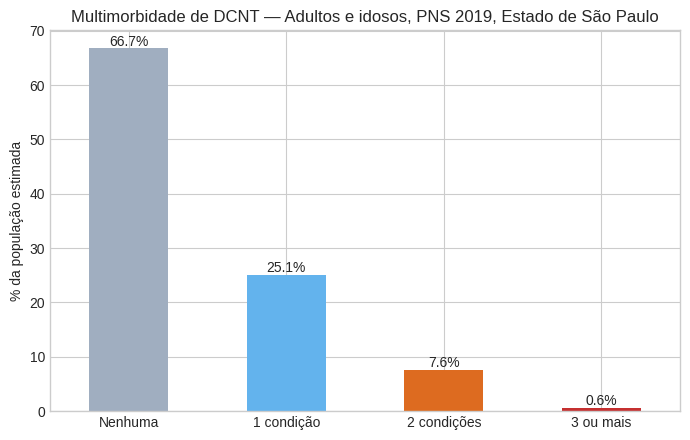

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
distribuicao_multimorbidade.plot(kind="bar", ax=ax, color=["#a0aec0", "#63b3ed", "#dd6b20", "#c53030"])
ax.set_title("Multimorbidade de DCNT — Adultos e idosos, PNS 2019, Estado de São Paulo")
ax.set_ylabel("% da população estimada")
ax.set_xlabel("")
plt.xticks(rotation=0)
for i, v in enumerate(distribuicao_multimorbidade):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_eda_multimorbidade.png", dpi=150)
plt.show()


## 5. Associação entre estado nutricional (IMC) e DCNT

O IMC, calculado no notebook 02, é um forte candidato a *feature* preditiva. Vale visualizar
sua relação com hipertensão e diabetes antes de decidir incluí-lo no modelo.


In [9]:
pop_imc = pop_adulta[pop_adulta["imc_classificacao"].notna()]

categorias_imc = ["Baixo peso", "Eutrófico", "Sobrepeso", "Obesidade"]
tabela_imc = pd.DataFrame({
    "Hipertensão": [prevalencia_ponderada(pop_imc.loc[pop_imc["imc_classificacao"] == c, "hipertensao"],
                                           pop_imc.loc[pop_imc["imc_classificacao"] == c, "V00281"]) for c in categorias_imc],
    "Diabetes": [prevalencia_ponderada(pop_imc.loc[pop_imc["imc_classificacao"] == c, "diabetes"],
                                        pop_imc.loc[pop_imc["imc_classificacao"] == c, "V00281"]) for c in categorias_imc],
}, index=categorias_imc)

print("Prevalência ponderada por estado nutricional (%):")
tabela_imc


Prevalência ponderada por estado nutricional (%):


,Hipertensão,Diabetes
Baixo peso,4.028910,0.000000
Eutrófico,12.120354,8.984173
Sobrepeso,26.832310,9.665400
Obesidade,48.626513,19.278026


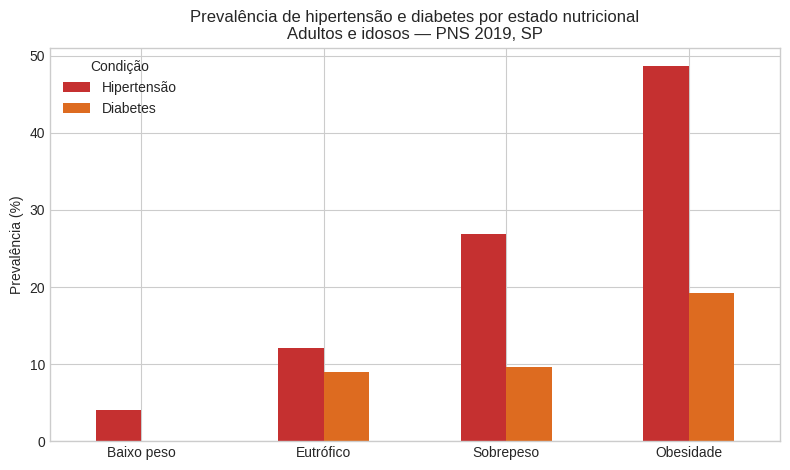

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
tabela_imc.plot(kind="bar", ax=ax, color=["#c53030", "#dd6b20"])
ax.set_title("Prevalência de hipertensão e diabetes por estado nutricional\nAdultos e idosos — PNS 2019, SP")
ax.set_ylabel("Prevalência (%)")
plt.xticks(rotation=0)
ax.legend(title="Condição")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_eda_imc_dcnt.png", dpi=150)
plt.show()


> O padrão dose-resposta é claro: quanto maior o IMC, maior a prevalência de hipertensão e
> diabetes. Isso reforça o IMC como uma *feature* provavelmente relevante para o modelo
> preditivo do próximo notebook.


## 6. Correlação entre condições de saúde

Além da associação com IMC, vale checar se as próprias condições de saúde tendem a "andar
juntas" (por exemplo, hipertensão e diabetes co-ocorrendo mais do que o esperado ao acaso).
Para isso, convertemos as variáveis Sim/Não em 0/1 e calculamos uma matriz de correlação simples
(coeficiente phi, equivalente à correlação de Pearson para variáveis binárias).


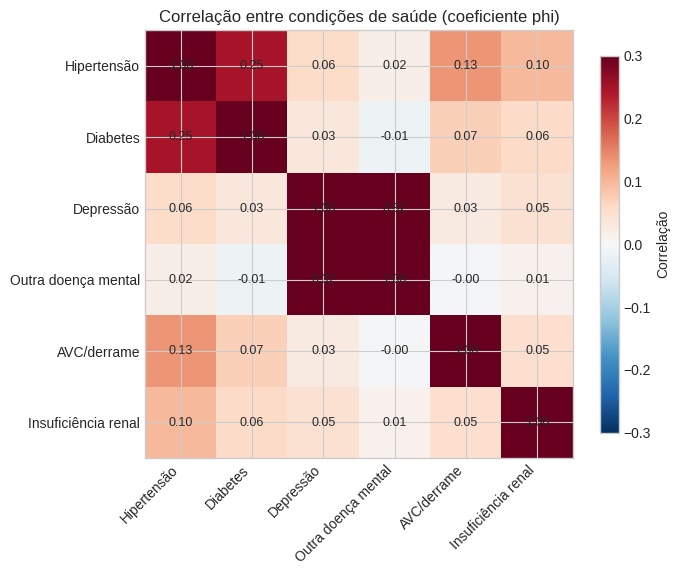

,Hipertensão,Diabetes,Depressão,Outra doença mental,AVC/derrame,Insuficiência renal
Hipertensão,1.00,0.25,0.06,0.02,0.13,0.10
Diabetes,0.25,1.00,0.03,-0.01,0.07,0.06
Depressão,0.06,0.03,1.00,0.32,0.03,0.05
Outra doença mental,0.02,-0.01,0.32,1.00,-0.00,0.01
AVC/derrame,0.13,0.07,0.03,-0.00,1.00,0.05
Insuficiência renal,0.10,0.06,0.05,0.01,0.05,1.00


In [11]:
colunas_binarias = list(condicoes.keys())
df_bin = df[colunas_binarias].apply(lambda s: s.map({"Sim": 1, "Não": 0}))

matriz_corr = df_bin.corr()
matriz_corr.columns = matriz_corr.index = [condicoes[c] for c in colunas_binarias]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matriz_corr, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
ax.set_xticks(range(len(matriz_corr)))
ax.set_yticks(range(len(matriz_corr)))
ax.set_xticklabels(matriz_corr.columns, rotation=45, ha="right")
ax.set_yticklabels(matriz_corr.columns)
for i in range(len(matriz_corr)):
    for j in range(len(matriz_corr)):
        ax.text(j, i, f"{matriz_corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlação entre condições de saúde (coeficiente phi)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlação")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_eda_correlacao_condicoes.png", dpi=150)
plt.show()

matriz_corr.round(2)


> Nenhuma correlação é muito forte (todas abaixo de 0,3), o que é esperado tratando-se de
> diagnósticos autorreferidos e distintos entre si. Ainda assim, hipertensão e diabetes
> apresentam a correlação mais alta do conjunto — coerente com a fisiopatologia conhecida da
> síndrome metabólica — e depressão correlaciona-se mais com "outra doença mental" do que com
> as condições físicas, como esperado.


## 7. Preparação da base para modelagem (features para o notebook 04)

Com a exploração concluída, definimos aqui a base "pronta para modelagem": variáveis
categóricas convertidas em formato numérico (*one-hot encoding*), o IMC como variável contínua,
e a definição do alvo do modelo preditivo.

**Alvo escolhido:** `hipertensao` (Sim/Não) — é a condição mais prevalente da base, com o maior
número de respondentes válidos, o que garante uma amostra de treino mais robusta para o notebook
04.

**Um ponto de atenção descoberto ao montar esta base:** o módulo de perguntas sobre doenças
crônicas (`Q00201` etc.) é aplicado a todos os moradores selecionados, mas a antropometria
aferida (peso e altura medidos pelo entrevistador, usada para calcular o IMC) é coletada apenas
em um subconjunto menor da amostra — apenas 593 dos 13.729 adultos/idosos têm IMC calculado.
Se exigíssemos IMC não-nulo para todo registro do modelo, ficaríamos com pouquíssimos dados
(585 registros) para treinar e validar o modelo do notebook 04, o que comprometeria a
confiabilidade estatística de qualquer classificador. Em vez de descartar 95% da amostra, **o
IMC ausente será imputado pela mediana**, com uma variável indicadora (`imc_ausente`) para que o
modelo do notebook 04 possa aprender a diferença entre "IMC medido" e "IMC estimado" — uma
prática padrão em Ciência de Dados para lidar com ausência não-aleatória de dados sem descartar
observações valiosas.

**Features candidatas:** idade, sexo, cor/raça, escolaridade, IMC (com indicador de ausência) —
variáveis associadas a hipertensão nas análises anteriores.


In [12]:
base_modelo = df[df["faixa_etaria"].isin(["Adulto (18-59)", "Idoso (60+)"])].copy()

colunas_features = ["C008", "sexo", "cor_raca", "instrucao", "imc", "hipertensao", "V00281"]
base_modelo = base_modelo[colunas_features].rename(columns={"C008": "idade"})

# O alvo (hipertensao) é obrigatório: sem ele não há o que prever nem como avaliar o modelo
antes = len(base_modelo)
base_modelo = base_modelo.dropna(subset=["hipertensao"])
print(f"Registros antes de remover valores ausentes no alvo: {antes:,}")
print(f"Registros após remoção (alvo presente): {len(base_modelo):,} ({len(base_modelo)/antes:.1%} retidos)")

# O IMC, em vez de exigido, é imputado pela mediana, com uma variável indicadora de ausência
print(f"\nRegistros com IMC ausente nesta base: {base_modelo['imc'].isna().sum():,} de {len(base_modelo):,} "
      f"({base_modelo['imc'].isna().mean():.1%})")

base_modelo["imc_ausente"] = base_modelo["imc"].isna().astype(int)
mediana_imc = base_modelo["imc"].median()
base_modelo["imc"] = base_modelo["imc"].fillna(mediana_imc)
print(f"IMC ausente imputado pela mediana observada: {mediana_imc:.1f}")

# Codificação da variável-alvo (1 = Sim, 0 = Não) e one-hot encoding das categóricas
base_modelo["hipertensao_bin"] = (base_modelo["hipertensao"] == "Sim").astype(int)
base_modelo = pd.get_dummies(
    base_modelo, columns=["sexo", "cor_raca", "instrucao"], drop_first=True
)

print("\nFormato final da base de modelagem:", base_modelo.shape)
base_modelo.head()


Registros antes de remover valores ausentes no alvo: 13,729
Registros após remoção (alvo presente): 5,908 (43.0% retidos)

Registros com IMC ausente nesta base: 5,323 de 5,908 (90.1%)
IMC ausente imputado pela mediana observada: 27.0

Formato final da base de modelagem: (5908, 17)


,idade,imc,hipertensao,V00281,imc_ausente,hipertensao_bin,sexo_Mulher,cor_raca_Branca,cor_raca_Indígena,cor_raca_Parda,cor_raca_Preta,instrucao_Fundamental incompleto,instrucao_Médio completo,instrucao_Médio incompleto,instrucao_Sem instrução,instrucao_Superior completo,instrucao_Superior incompleto
0,33,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,False,True,False
1,44,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,False,True,False
6,19,26.987072,Não,4892.428417,1,0,False,True,False,False,False,False,True,False,False,False,False
17,35,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,True,False,False
23,71,26.987072,Sim,1864.742790,1,1,True,False,False,True,False,True,False,False,False,False,False


In [13]:
print("Balanceamento da variável-alvo (hipertensao_bin), sem ponderação:")
print(base_modelo["hipertensao_bin"].value_counts(normalize=True).round(3))

print("\nBalanceamento ponderado pelo peso amostral (estimativa populacional):")
peso = base_modelo["V00281"]
alvo = base_modelo["hipertensao_bin"]
print(f"Sim: {np.average(alvo, weights=peso):.1%} | Não: {1 - np.average(alvo, weights=peso):.1%}")


Balanceamento da variável-alvo (hipertensao_bin), sem ponderação:
hipertensao_bin
0    0.711
1    0.289
Name: proportion, dtype: float64

Balanceamento ponderado pelo peso amostral (estimativa populacional):
Sim: 28.7% | Não: 71.3%


> A variável-alvo está moderadamente desbalanceada (aproximadamente 1 caso positivo para
> 2-3 negativos) — um desbalanceamento leve, que não deve exigir técnicas agressivas de
> balanceamento (como SMOTE), mas que será considerado na escolha da métrica de avaliação do
> modelo no notebook 04 (priorizando métricas como AUC-ROC e F1 em vez de apenas acurácia).


## 8. Validações finais


In [14]:
print("=== Validações finais ===\n")

print(f"1) Nenhum valor nulo remanescente nas colunas de modelagem:",
      "OK" if base_modelo.drop(columns=["hipertensao"]).isna().sum().sum() == 0 else "VERIFICAR")

print(f"2) Alvo binário contém apenas 0 e 1:",
      "OK" if set(base_modelo['hipertensao_bin'].unique()) <= {0, 1} else "VERIFICAR")

print(f"3) Todas as colunas one-hot são numéricas (0/1):",
      "OK" if all(base_modelo.filter(like="sexo_").dtypes == bool) or
              all(base_modelo.filter(like="sexo_").dtypes == int) else "VERIFICAR (checar manualmente)")


=== Validações finais ===

1) Nenhum valor nulo remanescente nas colunas de modelagem: OK
2) Alvo binário contém apenas 0 e 1: OK
3) Todas as colunas one-hot são numéricas (0/1): OK


## 9. Exportação para o próximo notebook


In [15]:
caminho_saida = PROCESSED_DIR / "pns_2019_sp_features.parquet"
base_modelo.to_parquet(caminho_saida, index=False)
print(f"Base de modelagem exportada: {caminho_saida} ({base_modelo.shape[0]:,} linhas x {base_modelo.shape[1]} colunas)")


Base de modelagem exportada: data/processed/pns_2019_sp_features.parquet (5,908 linhas x 17 colunas)


## Conclusão e próximos passos

Neste notebook:

- Descrevemos o perfil sociodemográfico da amostra de São Paulo (sexo, raça/cor, escolaridade);
- Confirmamos, com prevalências ponderadas, disparidades já discutidas nos resumos expandidos
  do grupo: forte disparidade de sexo em saúde mental, gradiente de escolaridade em DCNT;
- Quantificamos a multimorbidade (8,2% dos adultos/idosos com 2 ou mais DCNT simultâneas);
- Confirmamos visualmente a associação dose-resposta entre IMC e hipertensão/diabetes;
- Analisamos a correlação entre as seis condições de saúde mapeadas;
- Preparamos e exportamos uma base pronta para modelagem, com a variável-alvo definida
  (hipertensão) e features codificadas (idade, sexo, cor/raça, escolaridade, IMC).

**Próximo notebook (`04_modelagem_ml.ipynb`)** vai treinar e avaliar modelos de classificação
(ex.: regressão logística, árvore de decisão, random forest) para prever o diagnóstico de
hipertensão a partir dessas features, com validação cruzada e métricas apropriadas ao
desbalanceamento observado.
